# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult

from halcyon.Models.PhoenixModels import PhoenixAddAndProdLayers
from halcyon.Models.BaseLineModels import AlwaysDerivativeZero
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel

from halcyon.TidyDfResults import TidyDfResults

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

In [2]:
print(mlflow.get_tracking_uri())
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

https://mlflow.cropresilience.org


In [3]:
simulation_run_id_to_use = "72e5027402c2484db8acade9e9872170"

run = mlflow.get_run(simulation_run_id_to_use)

params = run.data.params
print(params)


{'nr_genes': '20', 'sparsity': '0.1', 'num_modules': '4', 'noise_level': 'ALLNOISE', 'seed': '174'}


In [4]:
parent_run_id_search_string = f"tags.mlflow.parentRunId= '{simulation_run_id_to_use}'" 
runs_to_download = mlflow.search_runs(filter_string=parent_run_id_search_string, output_format="list")

In [15]:
runs_to_download[0].data.params

{'nr_epochs': '0',
 'batch_size': '8',
 'loss_fn': 'MSELossFlexible',
 'model_class': 'AlwaysDerivativeZero'}

In [5]:
tidy_df = TidyDfResults.from_mlflow_runs(runs_to_download)
tidy_df.df.head()

2026-02-13 15:06:56,584 - INFO - Downloading artifacts for run 1f6cd5648ece43bf97554fe2353bab03


2026-02-13 15:07:00,819 - INFO - Downloading artifacts for run 12c155db659f4bc1b1c470d206e898b1


2026-02-13 15:07:01,857 - INFO - Downloading artifacts for run ee74adc450ee4a33b9690f4107602ad7


2026-02-13 15:07:02,822 - INFO - Downloading artifacts for run b29ea49d059b40438230917a6396ed56


2026-02-13 15:07:03,774 - INFO - Downloading artifacts for run 785d269b9a304ec39fe3a8dce03d3976


2026-02-13 15:07:04,749 - INFO - Downloading artifacts for run 88985511484a4d9e886bb1942b601d2a


,gene,time,predicted_expression,ground_truth,condition,run_id
0,Node_0,0.0,0.297446,0.297446,"KO: Node_2, Node_11. Env: None",1f6cd5648ece43bf97554fe2353bab03
1,Node_1,0.0,0.536181,0.536181,"KO: Node_2, Node_11. Env: None",1f6cd5648ece43bf97554fe2353bab03
2,Node_2,0.0,0.003108,0.003108,"KO: Node_2, Node_11. Env: None",1f6cd5648ece43bf97554fe2353bab03
3,Node_3,0.0,0.487081,0.487081,"KO: Node_2, Node_11. Env: None",1f6cd5648ece43bf97554fe2353bab03
4,Node_4,0.0,0.526255,0.526255,"KO: Node_2, Node_11. Env: None",1f6cd5648ece43bf97554fe2353bab03


# Plotting from tidydf

In [9]:
# Split into Single and Double knockout
tidy_df_single_ko, tidy_df_double_ko = tidy_df.split_into_single_and_double_ko()
tidy_df_double_ko.df['condition'].value_counts()


condition
KO: Node_1, Node_3. Env: None     2205
KO: Node_0, Node_7. Env: None     2205
KO: Node_1, Node_5. Env: None     2205
KO: Node_0, Node_3. Env: None     2205
KO: Node_1, Node_7. Env: None     2205
KO: Node_1, Node_9. Env: None     2205
KO: Node_2, Node_11. Env: None    2100
KO: Node_2, Node_12. Env: None    2100
KO: Node_2, Node_9. Env: None     2100
KO: Node_9, Node_12. Env: None    2100
KO: Node_0, Node_8. Env: None     2100
KO: Node_2, Node_8. Env: None     2100
KO: Node_0, Node_4. Env: None     2100
KO: Node_2, Node_5. Env: None     2100
KO: Node_0, Node_13. Env: None    2100
KO: Node_0, Node_2. Env: None     2100
KO: Node_4, Node_8. Env: None     2100
KO: Node_5, Node_9. Env: None     2100
KO: Node_0, Node_11. Env: None    2100
KO: Node_2, Node_4. Env: None     2100
Name: count, dtype: int64

In [ ]:
def df_selection_function(df):
    return ((df[TidyDfResults.GENE_COL].str.contains("Node_12|Node_2"))
            & (df[TidyDfResults.CONDITION_COL].str.contains("Node_12|Node_2")))

2026-02-13 17:12:09,442 - INFO - Getting model name for run_id 1f6cd5648ece43bf97554fe2353bab03
2026-02-13 17:12:09,638 - INFO - Getting model name for run_id 12c155db659f4bc1b1c470d206e898b1
2026-02-13 17:12:09,820 - INFO - Getting model name for run_id ee74adc450ee4a33b9690f4107602ad7
2026-02-13 17:12:09,986 - INFO - Getting model name for run_id b29ea49d059b40438230917a6396ed56
2026-02-13 17:12:10,151 - INFO - Getting model name for run_id 785d269b9a304ec39fe3a8dce03d3976
2026-02-13 17:12:10,306 - INFO - Getting model name for run_id 88985511484a4d9e886bb1942b601d2a


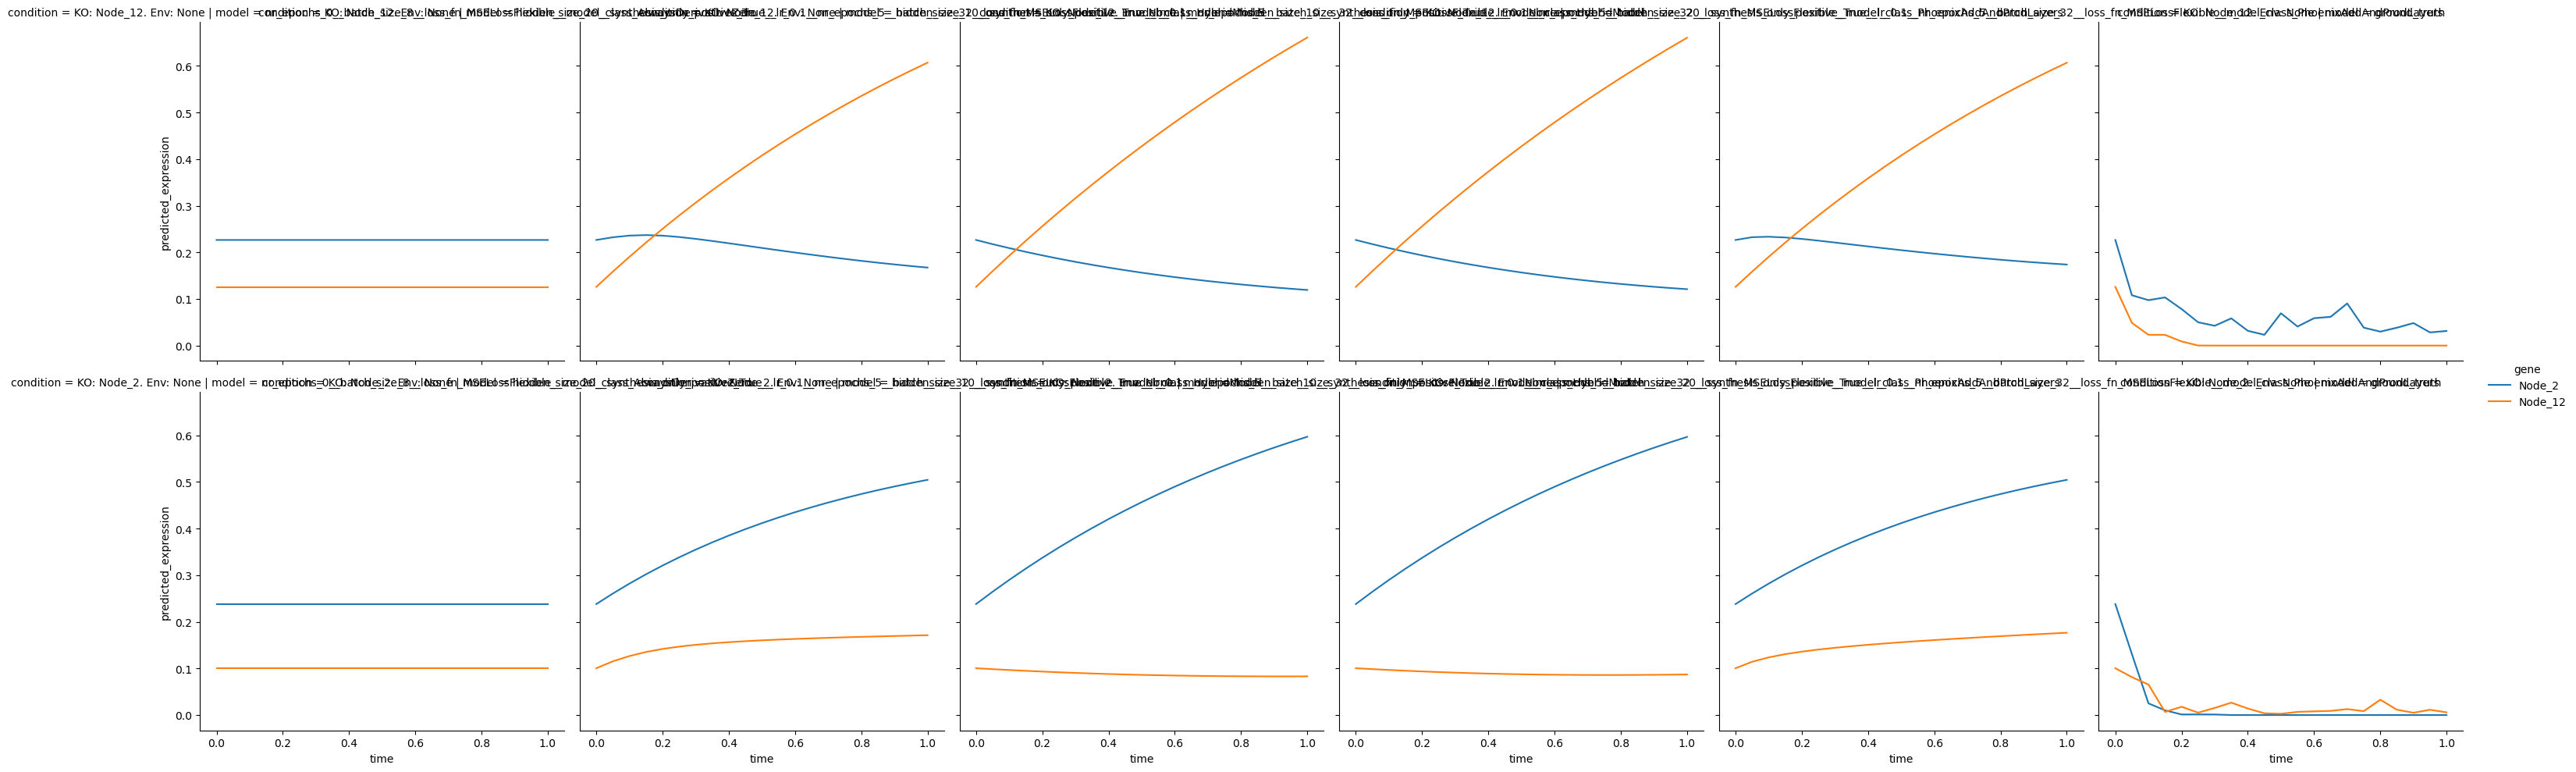

In [26]:
# FOr each of this knockout, plot predicted vs real for all model (for subset of genes)

# Plot for single KO
tidy_df_single_ko.plot_model_plots(df_selection_function=df_selection_function)

2026-02-13 17:16:51,774 - INFO - Getting model name for run_id 1f6cd5648ece43bf97554fe2353bab03
2026-02-13 17:16:51,964 - INFO - Getting model name for run_id 12c155db659f4bc1b1c470d206e898b1
2026-02-13 17:16:52,124 - INFO - Getting model name for run_id ee74adc450ee4a33b9690f4107602ad7
2026-02-13 17:16:52,289 - INFO - Getting model name for run_id b29ea49d059b40438230917a6396ed56
2026-02-13 17:16:52,445 - INFO - Getting model name for run_id 785d269b9a304ec39fe3a8dce03d3976
2026-02-13 17:16:52,599 - INFO - Getting model name for run_id 88985511484a4d9e886bb1942b601d2a


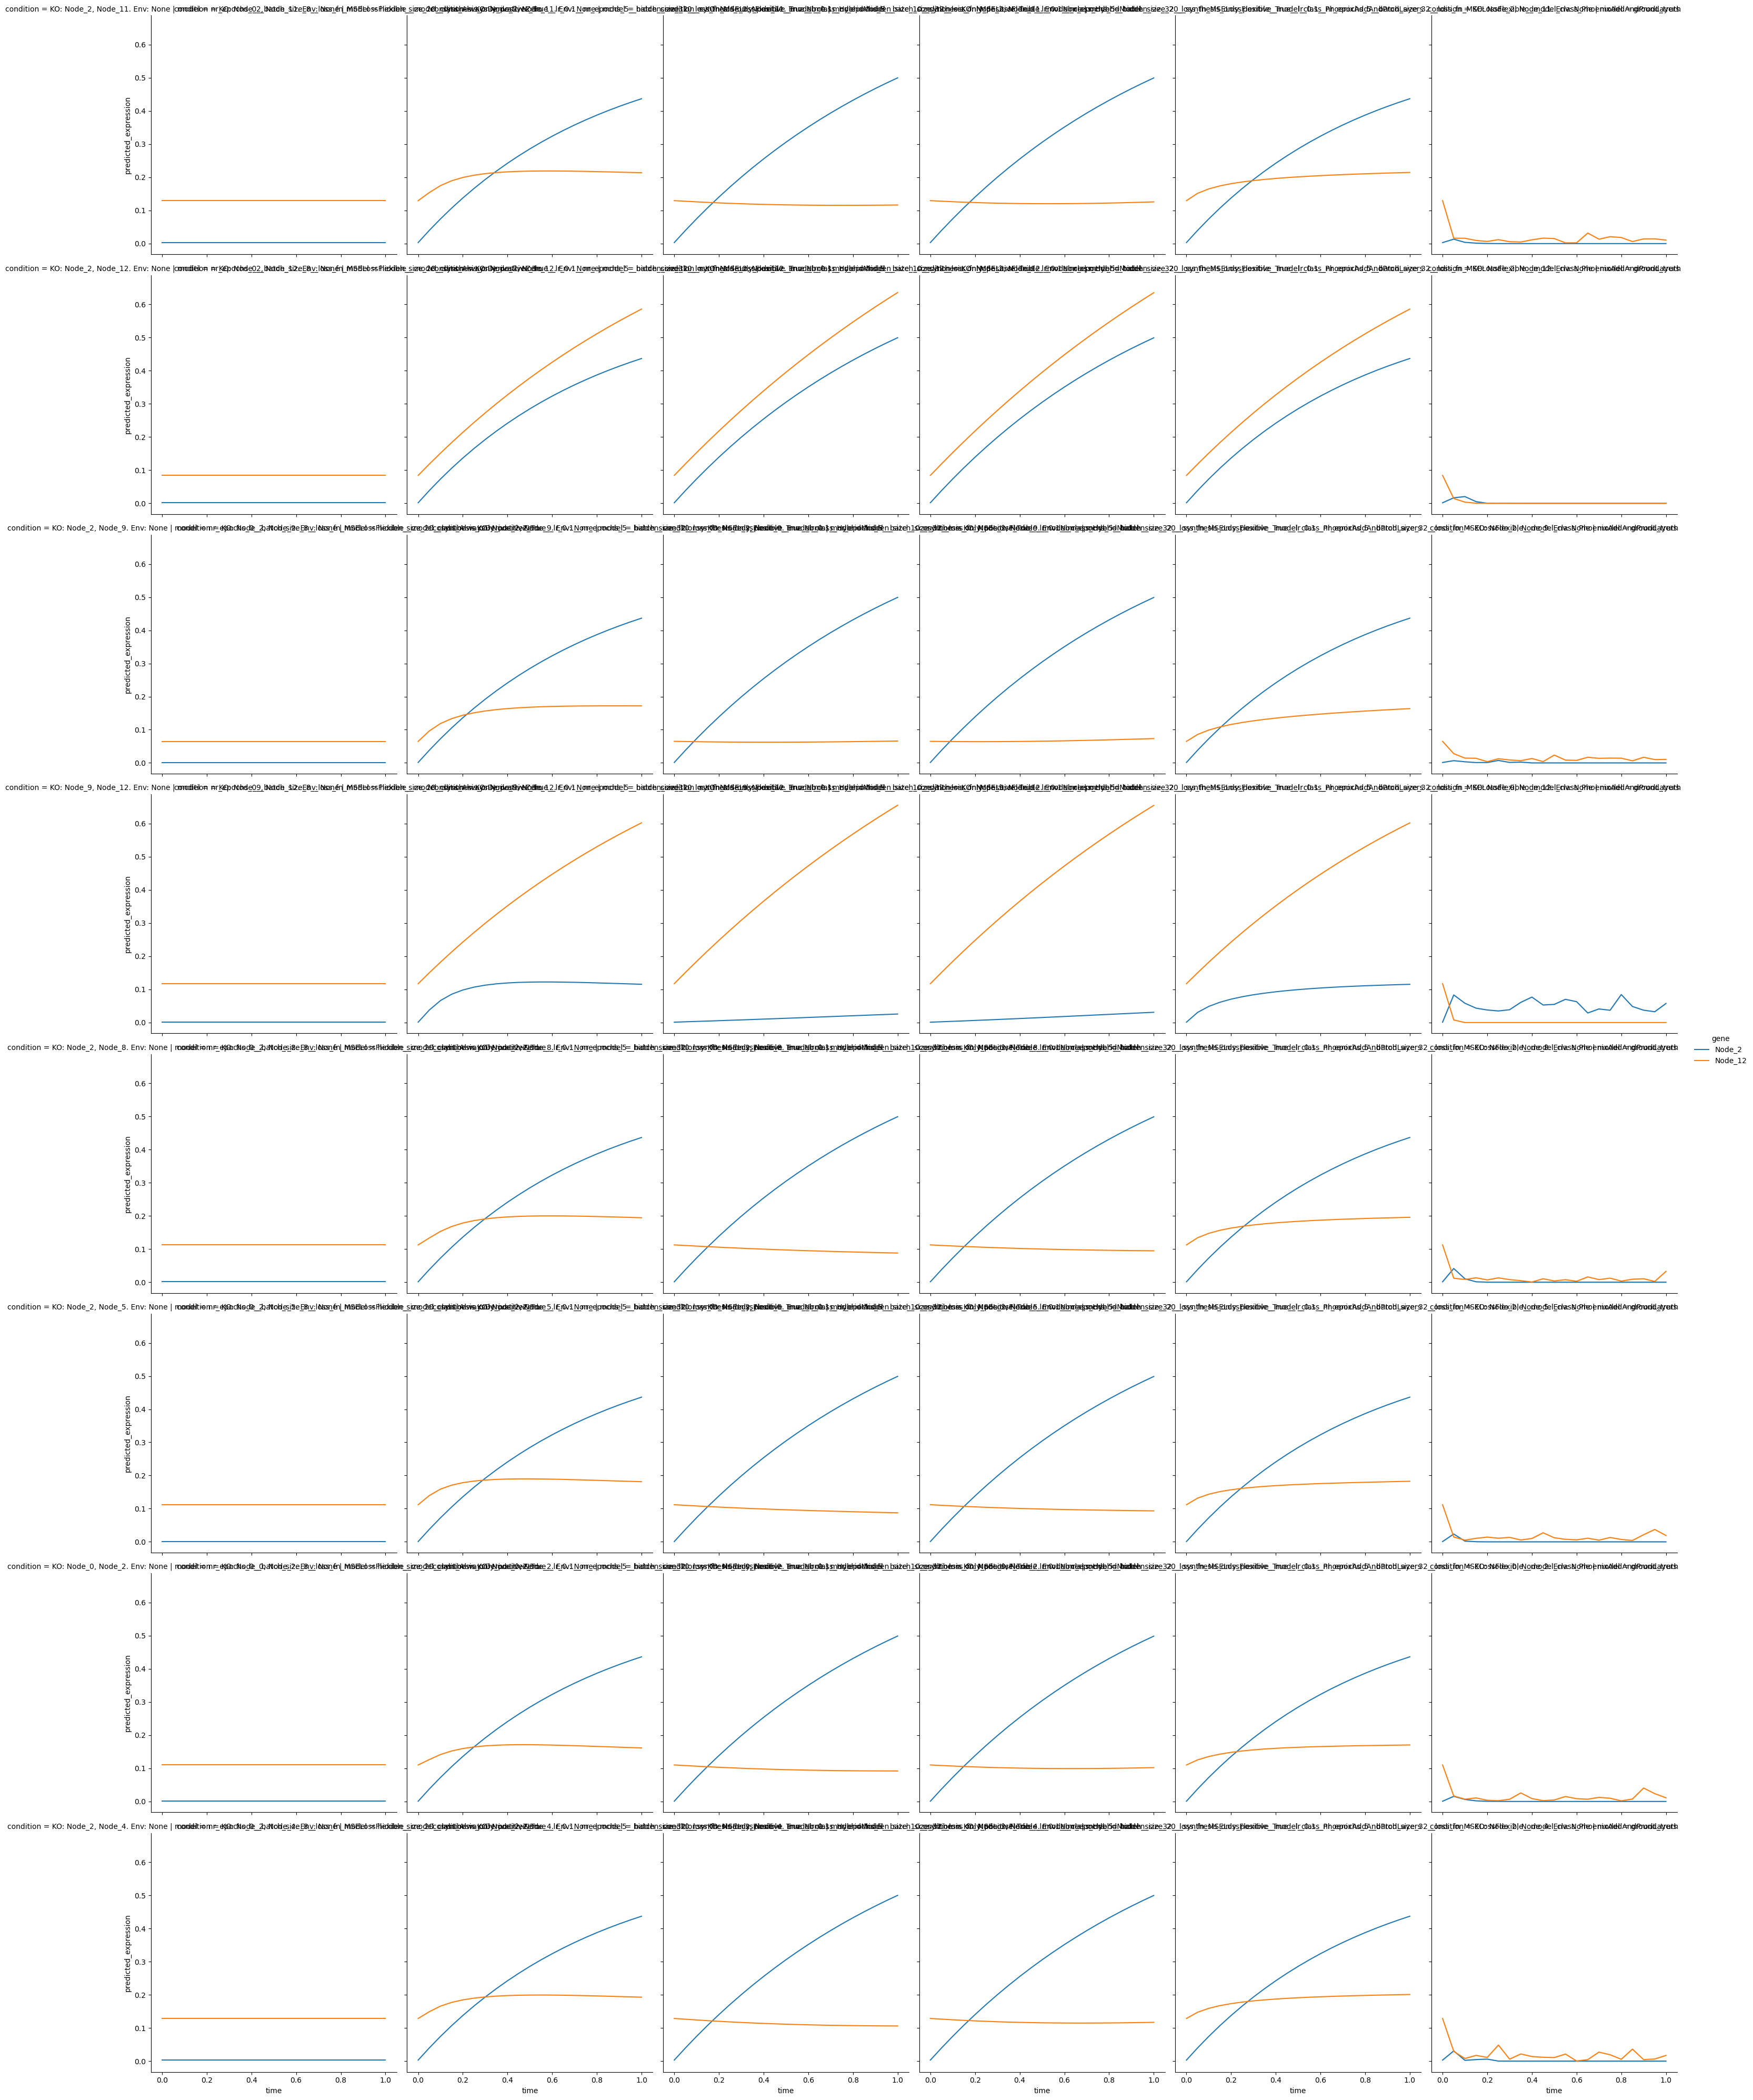

In [27]:
tidy_df_double_ko.plot_model_plots(df_selection_function=df_selection_function)

In [ ]:

# Calculate the MSE heatmap that we've shown before